In [98]:
import qiskit
import qiskit_ibm_runtime
import pylatexenc

from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import EstimatorV2 as Estimator
from qiskit.circuit import Parameter
from qiskit.circuit.library import UGate
from qiskit.circuit.library import RXGate
from qiskit.quantum_info import SparsePauliOp
from qiskit_ibm_runtime.fake_provider import FakeAlmadenV2
from qiskit.primitives import StatevectorEstimator

import numpy as np
from numpy import pi

from itertools import product

from matplotlib import pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors

<h1>Accurate CNOTs</h1>

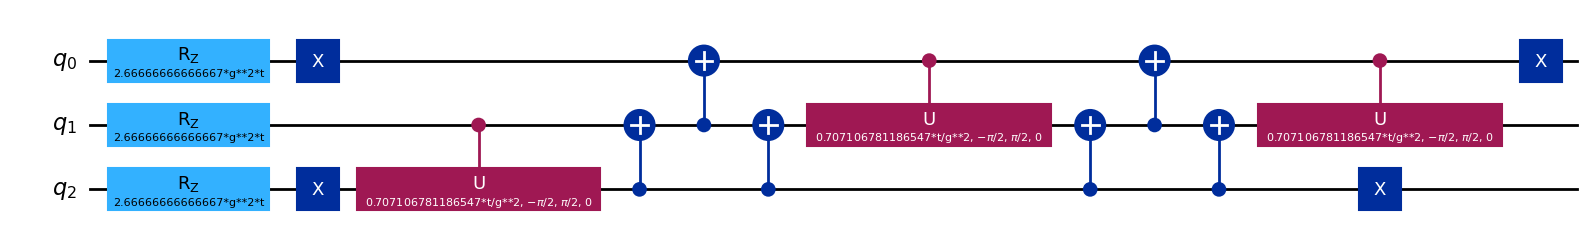

In [201]:
t = Parameter("t")
g = Parameter("g")

theta_E = (8 / 3) * g**2 * t
theta_B = 1 / (g**2 * np.sqrt(2)) * t

def one_step(n, N):
    qc = QuantumCircuit(n)
    
    for q in range(n):
        qc.rz(theta_E/N, q)

    for i in range(1, n - 1):
        # Flip controls from |0⟩ to |1⟩
        qc.x(i - 1)
        qc.x(i + 1)

        controlled_u = UGate(theta_B/N, -pi/2, pi/2).control(1)

        qc.append(controlled_u, [i, i + 1])
        qc.cx(i + 1, i)
        qc.cx(i, i - 1)
        qc.cx(i + 1, i)

        qc.append(controlled_u, [i - 1, i])
        qc.cx(i + 1, i)
        qc.cx(i, i - 1)
        qc.cx(i + 1, i)

        qc.append(controlled_u, [i - 1, i])

        # Flip back controls
        qc.x(i - 1)
        qc.x(i + 1)

    return qc

def N_steps_compose(n, N):
    one_step_circuit = one_step(n, N)
    full_circuit = QuantumCircuit(n)
    for _ in range(N):
        full_circuit.compose(one_step_circuit, inplace=True)
    return full_circuit

n = 3
N = 1
circuit = N_steps_compose(n, N)
circuit.draw("mpl")

In [203]:
observables_labels = ["IZI", "ZZI", "IZZ", "ZIZ"]
observables = [SparsePauliOp(label) for label in observables_labels]

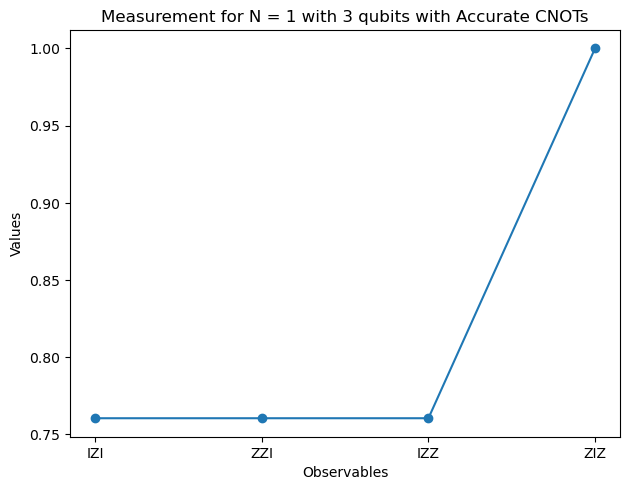

In [205]:
def plot_measurement_loop(n, N):
    circuit = N_steps_compose(n, N)
    pm = generate_preset_pass_manager(optimization_level=1)
    isa_circuit = pm.run(circuit)
    mapped_observables = [
        observable.apply_layout(isa_circuit.layout) for observable in observables
    ]

    estimator = StatevectorEstimator()
    job = estimator.run([(isa_circuit, mapped_observables, [1.0, 1.0])])
    
    result = job.result()
 
    pub_result = job.result()[0]

    values = pub_result.data.evs
    labels = observables_labels
    return labels, values

labels, values = plot_measurement_loop(3, 1)
plt.plot(labels, values, "-o")
plt.xlabel("Observables")
plt.ylabel("Values")
plt.tight_layout()
plt.title(f"Measurement for N = {N} with {n} qubits with Accurate CNOTs")
# plt.savefig(f'Accurate CNOT for {N} Steps.png')
plt.show()

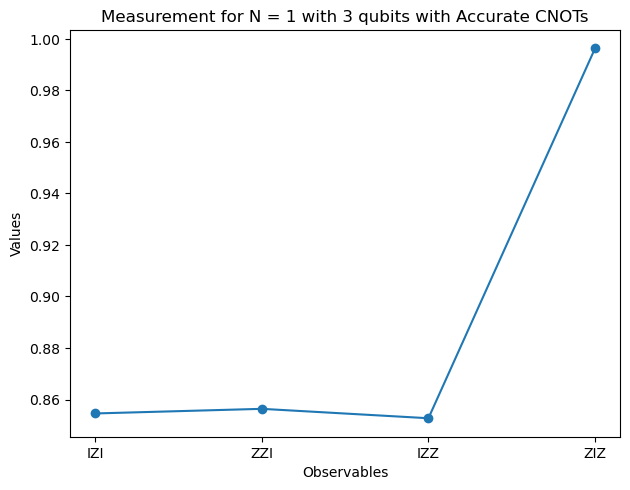

In [207]:
labels, values = plot_measurement_loop(3, 2)
plt.plot(labels, values, "-o")
plt.xlabel("Observables")
plt.ylabel("Values")
plt.tight_layout()
plt.title(f"Measurement for N = {N} with {n} qubits with Accurate CNOTs")
# plt.savefig(f'Accurate CNOT for {N} Steps.png')
plt.show()

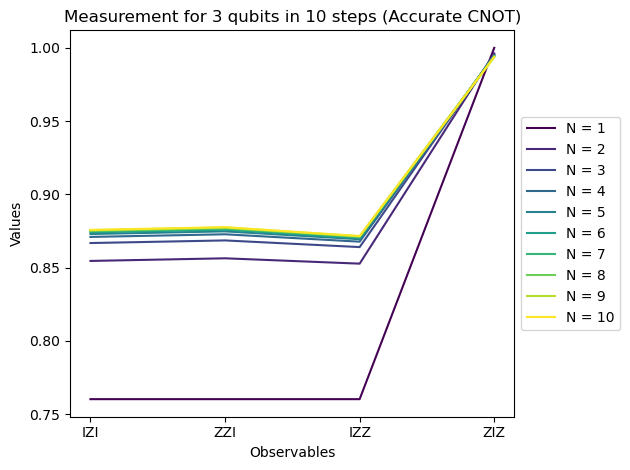

In [209]:
colors = cm.viridis(np.linspace(0, 1, 10))  # 10 colors evenly spaced

for idx, i in enumerate(np.arange(1, 11)):
    labels, values = plot_measurement_loop(3, i)
    plt.plot(labels, values, label=f"N = {i}", color=colors[idx])

plt.xlabel("Observables")
plt.ylabel("Values")
plt.title("Measurement for 3 qubits in 10 steps (Accurate CNOT)")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(f'Accurate CNOT 10 Steps for 3 Qubits.png')
plt.show()

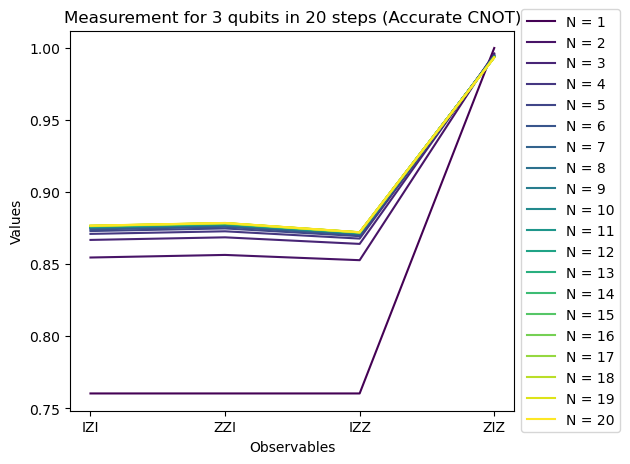

In [211]:
colors = cm.viridis(np.linspace(0, 1, 20))

for idx, i in enumerate(np.arange(1, 21)):
    labels, values = plot_measurement_loop(3, i)
    plt.plot(labels, values, label=f"N = {i}", color=colors[idx])

plt.xlabel("Observables")
plt.ylabel("Values")
plt.title("Measurement for 3 qubits in 20 steps (Accurate CNOT)")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(f'Accurate CNOT 20 Steps for 3 Qubits.png')
plt.show()

<h1>Traditional CNOTs</h1>

In [213]:
t = Parameter("t")
g = Parameter("g")

theta_E = (8 / 3) * g**2 * t
theta_B = 1 / (g**2 * np.sqrt(2)) * t

def one_step_trad(n, N):
    qc = QuantumCircuit(n)
    
    for q in range(n):
        qc.rz(theta_E/N, q)

    for i in range(1, n - 1):       
        qc.x(i - 1)
        qc.x(i + 1)
        
        qc.mcrx(2 * theta_B/N, [i - 1, i + 1], i)

        qc.x(i - 1)
        qc.x(i + 1)
    return qc

def N_steps_compose_trad(n, N):
    one_step_circuit = one_step_trad(n, N)
    full_circuit = QuantumCircuit(n)
    for _ in range(N):
        full_circuit.compose(one_step_circuit, inplace=True)
    return full_circuit

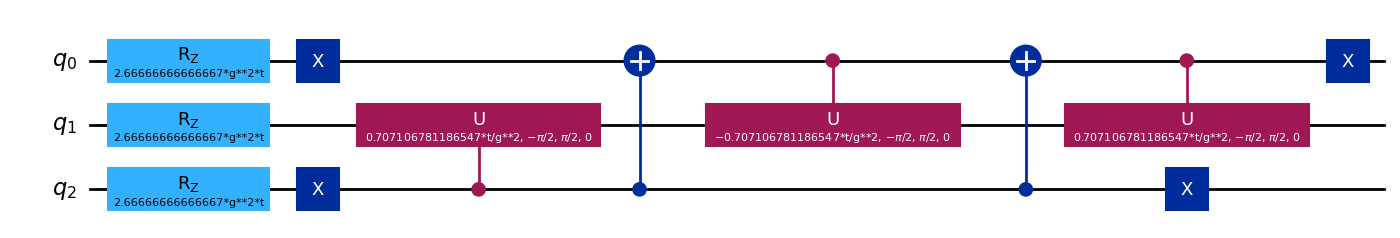

In [215]:
n = 3
N = 1
circuit = N_steps_compose_trad(n, N)
circuit.draw("mpl")

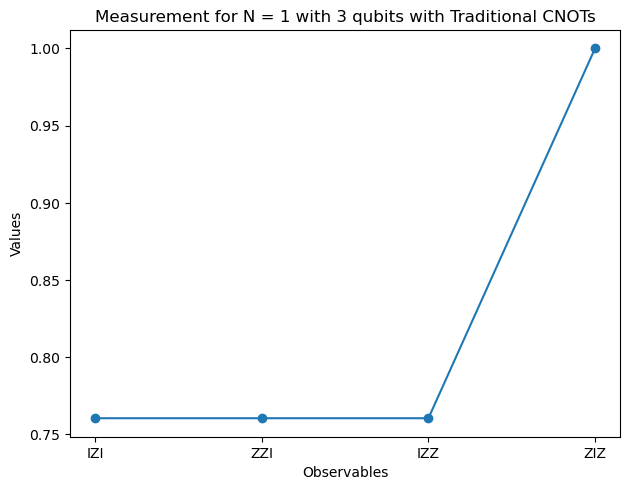

In [217]:
def plot_measurement_loop_trad(n, N):
    circuit = N_steps_compose_trad(n, N)
    pm = generate_preset_pass_manager(optimization_level=1)
    isa_circuit = pm.run(circuit)
    mapped_observables = [
        observable.apply_layout(isa_circuit.layout) for observable in observables
    ]

    estimator = StatevectorEstimator()
    job = estimator.run([(isa_circuit, mapped_observables, [1.0, 1.0])])
    
    result = job.result()
 
    pub_result = job.result()[0]

    values = pub_result.data.evs
    labels = observables_labels
    return labels, values

labels, values = plot_measurement_loop(3, 1)
plt.plot(labels, values, "-o")
plt.xlabel("Observables")
plt.ylabel("Values")
plt.tight_layout()
plt.title(f"Measurement for N = {N} with {n} qubits with Traditional CNOTs")
# plt.savefig(f'Accurate CNOT for {N} Steps.png')
plt.show()

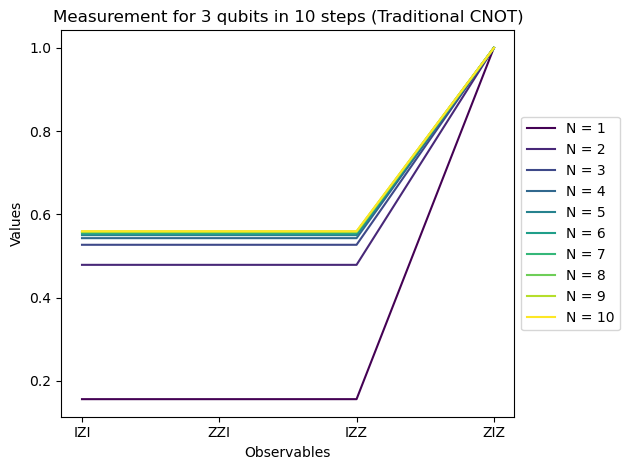

In [219]:
colors = cm.viridis(np.linspace(0, 1, 10))  # 10 colors evenly spaced

for idx, i in enumerate(np.arange(1, 11)):
    labels, values = plot_measurement_loop_trad(3, i)
    plt.plot(labels, values, label=f"N = {i}", color=colors[idx])

plt.xlabel("Observables")
plt.ylabel("Values")
plt.title("Measurement for 3 qubits in 10 steps (Traditional CNOT)")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(f'Traditional CNOT 10 Steps for 3 Qubits.png')
plt.show()

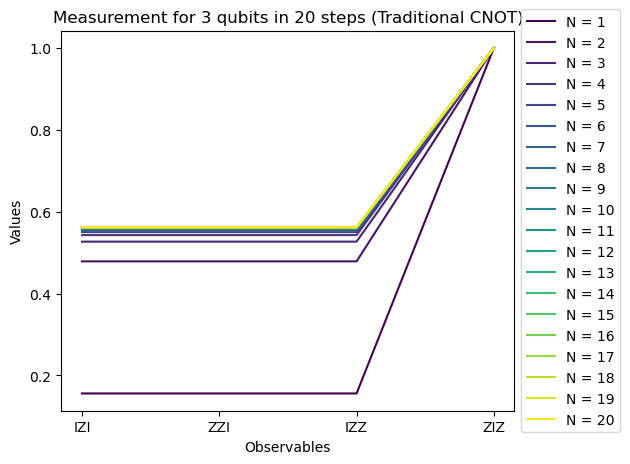

In [221]:
colors = cm.viridis(np.linspace(0, 1, 20))

for idx, i in enumerate(np.arange(1, 21)):
    labels, values = plot_measurement_loop_trad(3, i)
    plt.plot(labels, values, label=f"N = {i}", color=colors[idx])

plt.xlabel("Observables")
plt.ylabel("Values")
plt.title("Measurement for 3 qubits in 20 steps (Traditional CNOT)")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(f'Traditional CNOT 20 Steps for 3 Qubits.png')
plt.show()

<h1>New CNOTs</h1>

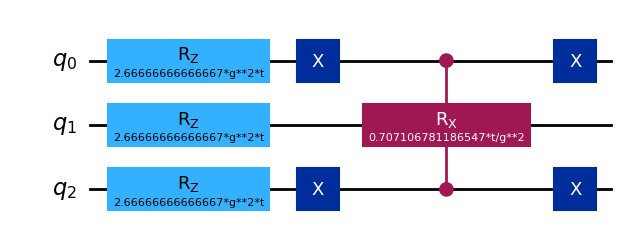

In [189]:
t = Parameter("t")
g = Parameter("g")

theta_E = (8 / 3) * g**2 * t
theta_B = 1 / (g**2 * np.sqrt(2)) * t

def one_step_new(n, N):
    qc = QuantumCircuit(n)
    
    for q in range(n):
        qc.rz(theta_E/N, q)

    for i in range(1, n - 1):       
        qc.x(i - 1)
        qc.x(i + 1)
        
        controlled_rx = RXGate(theta_B/N).control(2)  # 2 control qubits
        qc.append(controlled_rx, [i - 1, i + 1, i])

        qc.x(i - 1)
        qc.x(i + 1)
        
    return qc

def N_steps_compose_new(n, N):
    one_step_circuit = one_step_new(n, N)
    full_circuit = QuantumCircuit(n)
    for _ in range(N):
        full_circuit.compose(one_step_circuit, inplace=True)
    return full_circuit

n = 3
N = 1
circuit = N_steps_compose_new(n, N)
circuit.draw("mpl")

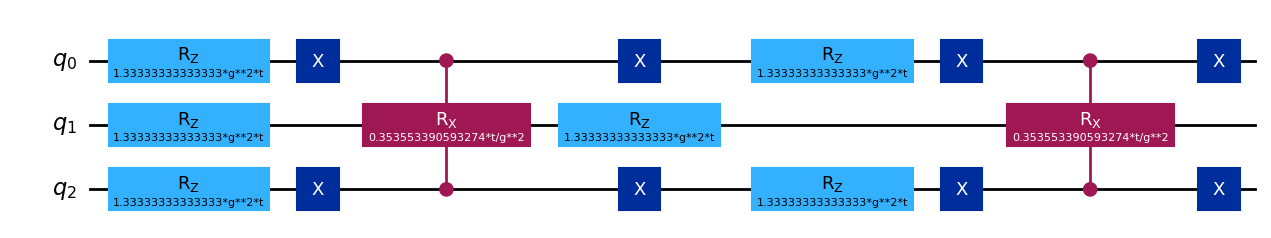

In [191]:
n = 3
N = 2
circuit = N_steps_compose_new(n, N)
circuit.draw("mpl")

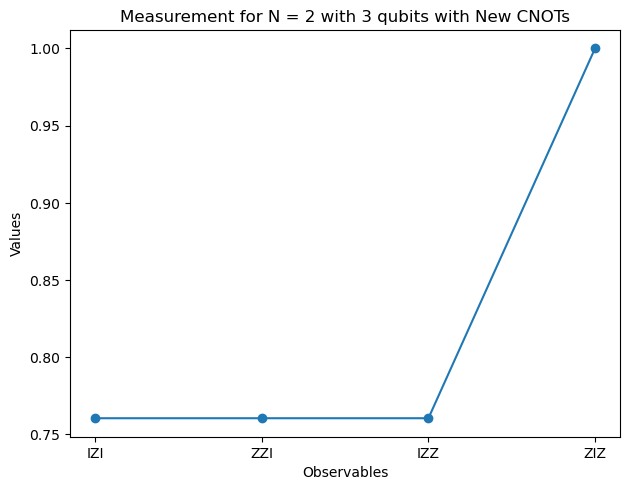

In [193]:
def plot_measurement_loop_new(n, N):
    circuit = N_steps_compose_new(n, N)
    pm = generate_preset_pass_manager(optimization_level=1)
    isa_circuit = pm.run(circuit)
    mapped_observables = [
        observable.apply_layout(isa_circuit.layout) for observable in observables
    ]

    estimator = StatevectorEstimator()
    job = estimator.run([(isa_circuit, mapped_observables, [1.0, 1.0])])
    
    result = job.result()
 
    pub_result = job.result()[0]

    values = pub_result.data.evs
    labels = observables_labels
    return labels, values

labels, values = plot_measurement_loop_new(3, 1)
plt.plot(labels, values, "-o")
plt.xlabel("Observables")
plt.ylabel("Values")
plt.tight_layout()
plt.title(f"Measurement for N = {N} with {n} qubits with New CNOTs")
# plt.savefig(f'New CNOT for {N} Steps.png')
plt.show()

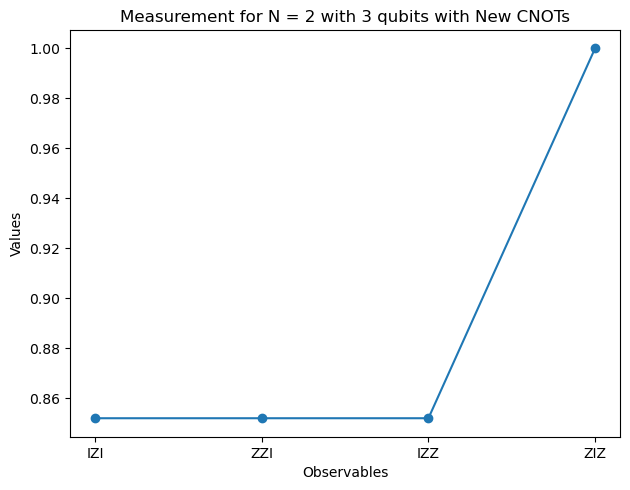

In [195]:
def plot_measurement_loop_new(n, N):
    circuit = N_steps_compose_new(n, N)
    pm = generate_preset_pass_manager(optimization_level=1)
    isa_circuit = pm.run(circuit)
    mapped_observables = [
        observable.apply_layout(isa_circuit.layout) for observable in observables
    ]

    estimator = StatevectorEstimator()
    job = estimator.run([(isa_circuit, mapped_observables, [1.0, 1.0])])
    
    result = job.result()
 
    pub_result = job.result()[0]

    values = pub_result.data.evs
    labels = observables_labels
    return labels, values

labels, values = plot_measurement_loop_new(3, 2)
plt.plot(labels, values, "-o")
plt.xlabel("Observables")
plt.ylabel("Values")
plt.tight_layout()
plt.title(f"Measurement for N = {N} with {n} qubits with New CNOTs")
# plt.savefig(f'New CNOT for {N} Steps.png')
plt.show()

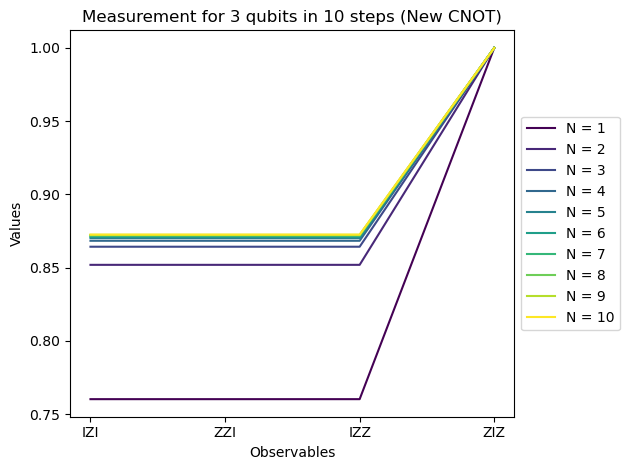

In [237]:
colors = cm.viridis(np.linspace(0, 1, 10))  # 10 colors evenly spaced

for idx, i in enumerate(np.arange(1, 11)):
    labels, values = plot_measurement_loop_new(3, i)
    plt.plot(labels, values, label=f"N = {i}", color=colors[idx])

plt.xlabel("Observables")
plt.ylabel("Values")
plt.title("Measurement for 3 qubits in 10 steps (New CNOT)")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(f'New CNOT 10 Steps for 3 Qubits.png')
plt.show()

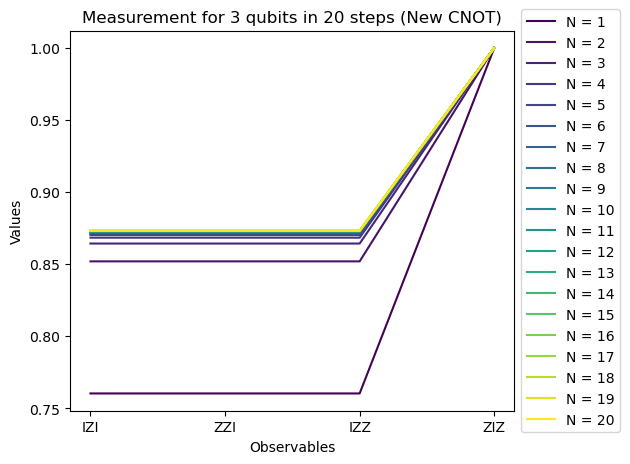

In [199]:
colors = cm.viridis(np.linspace(0, 1, 20))

for idx, i in enumerate(np.arange(1, 21)):
    labels, values = plot_measurement_loop_new(3, i)
    plt.plot(labels, values, label=f"N = {i}", color=colors[idx])

plt.xlabel("Observables")
plt.ylabel("Values")
plt.title("Measurement for 3 qubits in 20 steps (New CNOT)")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(f'New CNOT 20 Steps for 3 Qubits.png')
plt.show()

<h3>Example from https://docs.quantum.ibm.com/api/qiskit/qiskit.circuit.ControlledGate</h3>

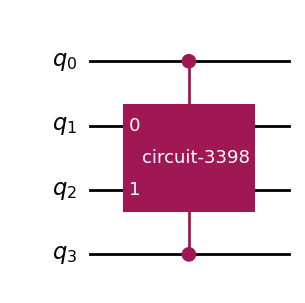

In [143]:
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.circuit.library.standard_gates import HGate
 
qc1 = QuantumCircuit(2)
qc1.x(0)
qc1.h(1)
custom = qc1.to_gate().control(2)
 
qc2 = QuantumCircuit(4)
qc2.append(custom, [0, 3, 1, 2])
qc2.draw('mpl')

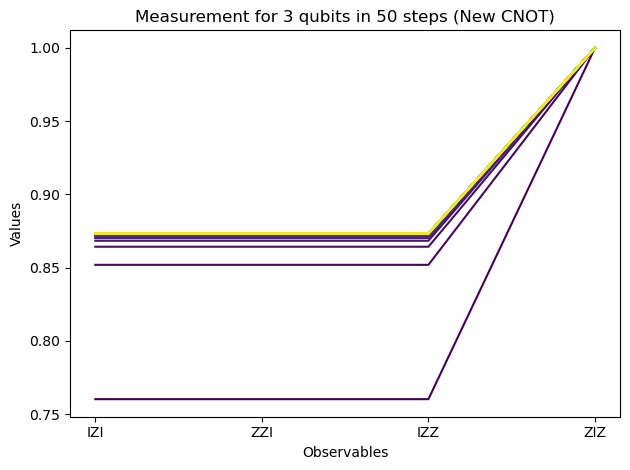

In [227]:
colors = cm.viridis(np.linspace(0, 1, 50))

for idx, i in enumerate(np.arange(1, 51)):
    labels, values = plot_measurement_loop_new(3, i)
    plt.plot(labels, values, label=f"N = {i}", color=colors[idx])

plt.xlabel("Observables")
plt.ylabel("Values")
plt.title("Measurement for 3 qubits in 50 steps (New CNOT)")
# plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(f'New CNOT 50 Steps for 3 Qubits.png')
plt.show()

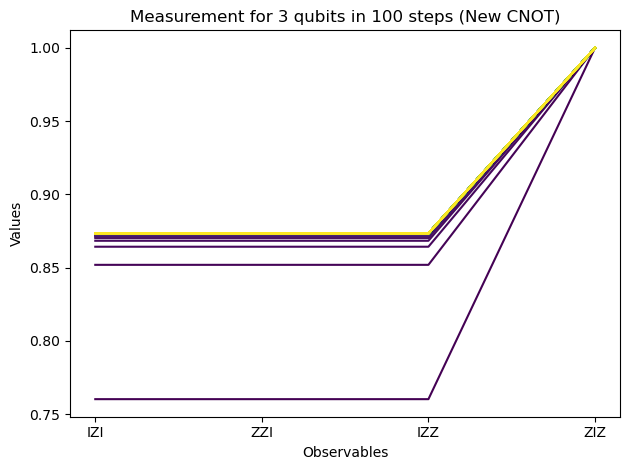

In [229]:
colors = cm.viridis(np.linspace(0, 1, 100))

for idx, i in enumerate(np.arange(1, 101)):
    labels, values = plot_measurement_loop_new(3, i)
    plt.plot(labels, values, label=f"N = {i}", color=colors[idx])

plt.xlabel("Observables")
plt.ylabel("Values")
plt.title("Measurement for 3 qubits in 100 steps (New CNOT)")
# plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.savefig(f'New CNOT 100 Steps for 3 Qubits.png')
plt.show()